In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score,
    accuracy_score,
    classification_report
)

In [2]:
# Load the dataset
data = load_breast_cancer()

# Convert dataset into a DataFrame
df = pd.DataFrame(data.data, columns=data.feature_names)

# Convert target:
# 1 = Malignant (Disease)
# 0 = Benign (No Disease)

df['diagnosis'] = (data.target == 0).astype(int)

# Display first five records
print(df.head())

# Display dataset information
print("\nDataset Shape:", df.shape)

# Count disease and healthy cases
print("\nDiagnosis Count:")
print(df['diagnosis'].value_counts())

   mean radius  mean texture  mean perimeter  mean area  mean smoothness  \
0        17.99         10.38          122.80     1001.0          0.11840   
1        20.57         17.77          132.90     1326.0          0.08474   
2        19.69         21.25          130.00     1203.0          0.10960   
3        11.42         20.38           77.58      386.1          0.14250   
4        20.29         14.34          135.10     1297.0          0.10030   

   mean compactness  mean concavity  mean concave points  mean symmetry  \
0           0.27760          0.3001              0.14710         0.2419   
1           0.07864          0.0869              0.07017         0.1812   
2           0.15990          0.1974              0.12790         0.2069   
3           0.28390          0.2414              0.10520         0.2597   
4           0.13280          0.1980              0.10430         0.1809   

   mean fractal dimension  ...  worst texture  worst perimeter  worst area  \
0             

In [3]:
X = df.drop('diagnosis', axis=1)

y = df['diagnosis']

print("Input Features:", X.shape)
print("Output Labels:", y.shape)

Input Features: (569, 30)
Output Labels: (569,)


In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

Training Data: (455, 30)
Testing Data: (114, 30)


In [5]:
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)

X_test = scaler.transform(X_test)

In [6]:
model = LogisticRegression(max_iter=1000)

# Train the model
model.fit(X_train, y_train)

# Predict test results
y_pred = model.predict(X_test)

print("Model Training Completed!")

Model Training Completed!


In [7]:
cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

print("Confusion Matrix:")
print(cm)

tn, fp, fn, tp = cm.ravel()

print("\nTrue Negative (TN):", tn)
print("False Positive (FP):", fp)
print("False Negative (FN):", fn)
print("True Positive (TP):", tp)

Confusion Matrix:
[[71  1]
 [ 3 39]]

True Negative (TN): 71
False Positive (FP): 1
False Negative (FN): 3
True Positive (TP): 39


In [8]:
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
accuracy = accuracy_score(y_test, y_pred)

print("Accuracy:", round(accuracy, 4))
print("Precision:", round(precision, 4))
print("Recall:", round(recall, 4))
print("F1-Score:", round(f1, 4))

Accuracy: 0.9649
Precision: 0.975
Recall: 0.9286
F1-Score: 0.9512


In [9]:
print("Classification Report:\n")

print(classification_report(
    y_test,
    y_pred,
    target_names=['No Disease', 'Disease']
))

Classification Report:

              precision    recall  f1-score   support

  No Disease       0.96      0.99      0.97        72
     Disease       0.97      0.93      0.95        42

    accuracy                           0.96       114
   macro avg       0.97      0.96      0.96       114
weighted avg       0.97      0.96      0.96       114



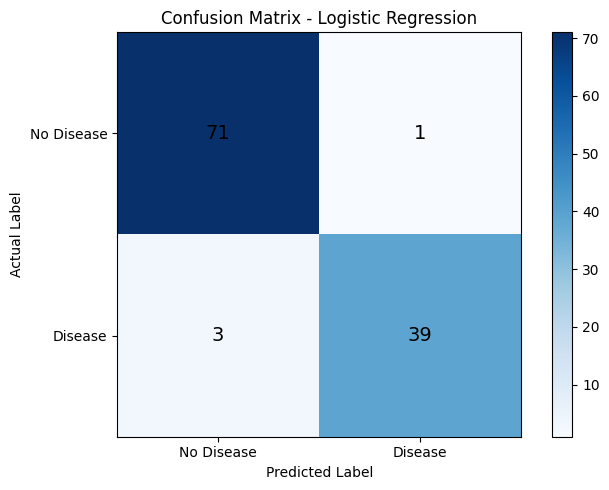

In [10]:
plt.figure(figsize=(7, 5))

plt.imshow(cm, cmap='Blues')

plt.title("Confusion Matrix - Logistic Regression")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")

plt.xticks([0, 1], ['No Disease', 'Disease'])
plt.yticks([0, 1], ['No Disease', 'Disease'])

for i in range(2):
    for j in range(2):
        plt.text(j, i, cm[i, j],
                 ha='center',
                 va='center',
                 fontsize=14)

plt.colorbar()
plt.tight_layout()
plt.show()

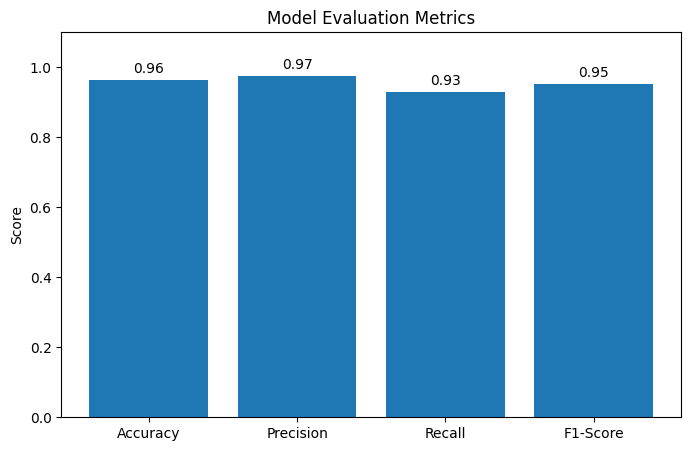

In [11]:
metrics = {
    'Accuracy': accuracy,
    'Precision': precision,
    'Recall': recall,
    'F1-Score': f1
}

plt.figure(figsize=(8, 5))

plt.bar(metrics.keys(), metrics.values())

plt.title("Model Evaluation Metrics")
plt.ylabel("Score")
plt.ylim(0, 1.1)

for i, value in enumerate(metrics.values()):
    plt.text(i, value + 0.02, f'{value:.2f}', ha='center')

plt.show()